# · GW strain data and instrument noise

**Goals:** inspect detector strain; estimate noise power spectral density (PSD); Pre-conditioning the GW data, understand whitening.

We use public **GW150914** strain data from H1 and L1 (GPS event time $1126259462.4$).

If the data hasn't already been downloaded, run from the repository root:

```bash
python download_data.py
```

This downloads 64 seconds of strain around GW150914 from GWOSC and creates:

```
data/
  GW150914_H1_4096Hz_64s.gwf
  GW150914_L1_4096Hz_64s.gwf
```

These are genuine gravitational-wave frame files containing the unfiltered 4096 Hz strain channel (`H1:GWOSC-4KHZ_R1_STRAIN` or `L1:GWOSC-4KHZ_R1_STRAIN`) and timestamps. During analysis we apply highpass filter and resample to 2048 Hz.

*“Will you see a black-hole merger in the raw time series?”* before plotting.


In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from pycbc.frame import read_frame
from pycbc.filter import highpass, resample_to_delta_t
from pycbc.psd import welch, interpolate, inverse_spectrum_truncation

/home/abhishek.sharma/miniconda3/envs/gw-env/lib/python3.11/site-packages/pycbc/types/array.py:36: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal as _lal
PyCBC.libutils: pkg-config call failed, setting NO_PKGCONFIG=1


In [3]:
GPS = 1126259462.4  # GW150914 geocentric GPS time
SAMPLING_FREQ = 2048  # analysis sampling frequency (Hz)
DURATION = 64
DATA_DIR = Path('../data')

# Also support launching Jupyter from inside the notebooks/ subdirectory.
if not DATA_DIR.is_dir() and Path('../data').is_dir():
    DATA_DIR = Path('../data')

def load_detector(ifo='H1'):

    """Read locally cached, unfiltered GWOSC strain and prepare it for analysis."""

    if ifo not in ('H1', 'L1'):
        raise ValueError('This workshop provides H1 and L1 data only.')
    
    path = DATA_DIR / f'GW150914_{ifo}_4096Hz_64s.gwf'
    channel = f'{ifo}:GWOSC-4KHZ_R1_STRAIN'
    
    if not path.exists():
        raise FileNotFoundError(f'{path} not found. From the repository root run: python download_data.py')
    
    raw = read_frame(str(path), channel)
    raw = raw.crop(2, 2)
    # if abs(float(raw.sample_rate) - 4096) > 1e-6 or len(raw) != DURATION * 4096:
    #     raise ValueError(f'Unexpected data length/rate in {path}; rerun download_data.py --force')
    
    return resample_to_delta_t(highpass(raw, 15.0), 1.0 / SAMPLING_FREQ)

def estimate_psd(data, f_low=20):
    
    seg = 4 * SAMPLING_FREQ
    psd = welch(data, seg_len=seg, seg_stride=seg//2)
    # PSD for visualization uses its native frequency bins; match-filter PSD
    # would need interpolation to the FFT frequency grid of the data.
    return psd

# Function to whiten a frequency series `freqSeries` colored with `PSD`.
def whiten(freqSeries, PSD):

    PSD.data[np.where(PSD.data == 0)[0]] = 10**(-50)
    whiten_strain = (freqSeries / (PSD/freqSeries.delta_t/2) ** 0.5).to_timeseries()

    return whiten_strain

plt.rcParams.update({'figure.figsize': (11, 4), 'font.size': 11})


In [4]:
# Load H1 and L1 strain data
h1 = load_detector('H1')
l1 = load_detector('L1')

# Print data information
for ifo, strain in [('H1', h1), ('L1', l1)]:
    print(f'{ifo}:')
    print('  Duration (s):', len(strain) * strain.delta_t)
    print('  Sampling rate (Hz):', strain.sample_rate)
    print('  Start GPS:', strain.start_time)

H1:
  Duration (s): 60.0
  Sampling rate (Hz): 2048.0
  Start GPS: 1126259432
L1:
  Duration (s): 60.0
  Sampling rate (Hz): 2048.0
  Start GPS: 1126259432


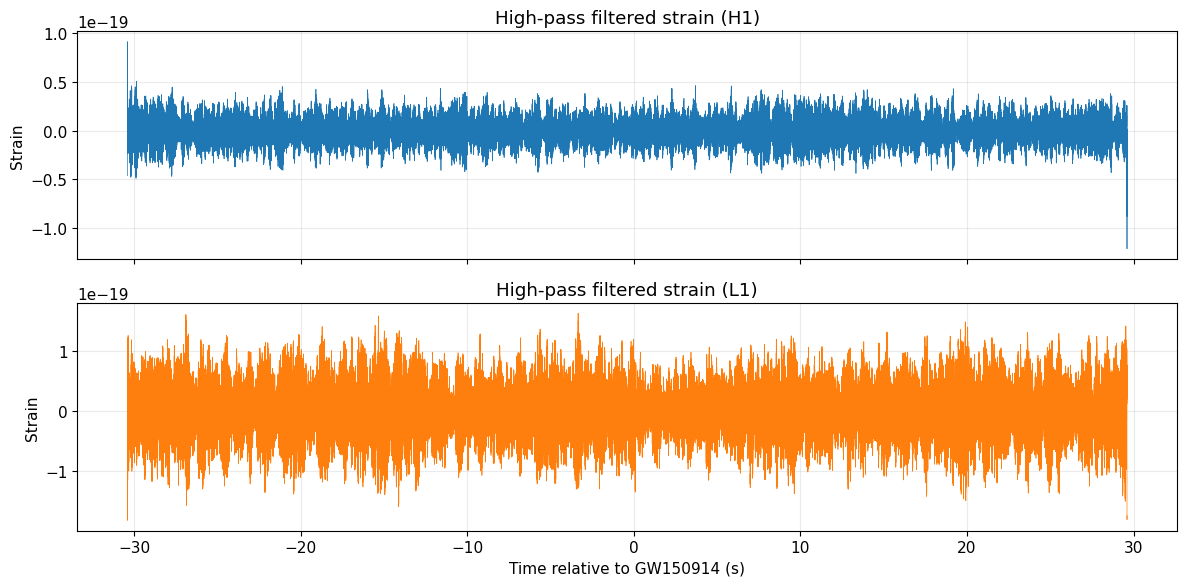

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

axes[0].plot(h1.sample_times - GPS, h1, lw=0.5)
axes[0].set_ylabel('Strain')
axes[0].set_title('High-pass filtered strain (H1)')
axes[0].grid(alpha=0.25)

axes[1].plot(l1.sample_times - GPS, l1, lw=0.5, color='tab:orange')
axes[1].set_ylabel('Strain')
axes[1].set_title('High-pass filtered strain (L1)')
axes[1].set_xlabel('Time relative to GW150914 (s)')
axes[1].grid(alpha=0.25)

# axes[1].set_xlim(-5, 5)

plt.tight_layout()
plt.show()

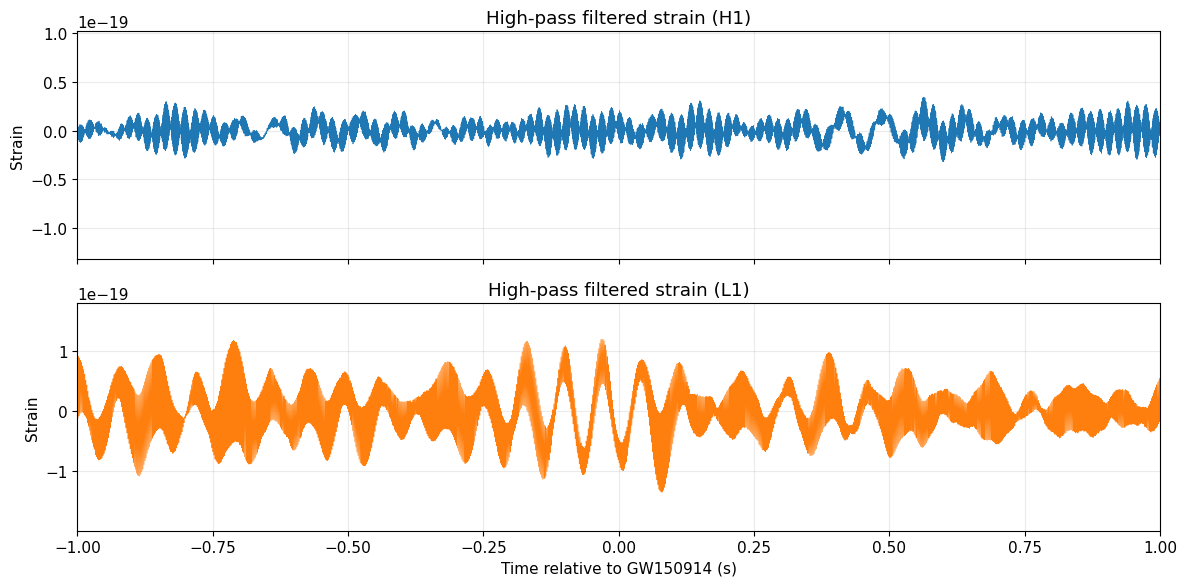

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

axes[0].plot(h1.sample_times - GPS, h1, lw=0.5)
axes[0].set_ylabel('Strain')
axes[0].set_title('High-pass filtered strain (H1)')
axes[0].grid(alpha=0.25)

axes[1].plot(l1.sample_times - GPS, l1, lw=0.5, color='tab:orange')
axes[1].set_ylabel('Strain')
axes[1].set_title('High-pass filtered strain (L1)')
axes[1].set_xlabel('Time relative to GW150914 (s)')
axes[1].grid(alpha=0.25)

axes[1].set_xlim(-1, )

plt.tight_layout()
plt.show()

### [Fourier transform](https://en.wikipedia.org/wiki/Fourier_transform)

The Fourier transform is a widely-used mathematical tool to expose the frequency-domain content of a time-domain signal $s(t)$, meaning we can see which frequencies contain lots of power, and which have less.

For a given frequency $f$, the Fourier transform of $s(t)$ is:
$$
\tilde{s}(f) = \int_{-\infty}^{+\infty} s(t) e^{- i \times 2\pi f t} dt
$$
The Fourier transform is a complex-valued function of $f$. For real-valued signals, positive and negative frequencies are redundant as $\tilde{s}(-f) = \tilde{s}^*(f)$.

The resolution in frequency domain is controlled by the duration of the signal in time-domain.

$$
\Delta f = 1 / T
$$

### [Power Spectral Density (PSD)](https://en.wikipedia.org/wiki/Spectral_density)

Detector output also contains instrumental and environmental noise. Even when a signal is present, raw strain can look like noise. The **power spectral density (PSD)**, $S_n(f)$, describes noise power per hertz and has units $1/\mathrm{Hz}$ for dimensionless strain.

Given a data stretch of length $T$, one definition for the PSD of stationary noise $S_n(f)$ is
$$ S_{n}(f) = \lim_{T \rightarrow +\infty} \frac{2}{T} \langle \left| \tilde{n}_{T}(f) \right|^{2} \rangle$$
meaning that the PSD measures the spectral shape of the noise time series. Another useful definition is
$$ \frac{1}{2} S_{n}(f) = \int d\tau \, e^{-2 i \pi f \tau} C_n(\tau)$$
where $C_{n}(\tau)$ is the noise autocorrelation function (which depends only on lag in the case of stationary noise)
$$ C_{n}(\tau) = \langle n(t) n(t+\tau)\rangle$$

The stationarity is what gives us the following crucial property: the FD noise in different bins is independent. In the continuous-limit notations for infinitely long signals,
$$\langle\tilde{n}(f) \tilde{n}^*(f')\rangle = \frac{1}{2} S_n(f) \delta(f - f')$$

Incorporating the fact that we always work with a finite duration $T$ and discrete frequencies, and only then take the limit of $T \rightarrow \infty$,
$$ \frac{2}{T}\langle \tilde{n}_T(f_k) \tilde{n}^{\ast}_T(f_l) \rangle \underset{T\to \infty}{\to} S_{n}(f_k) \delta_{kl} $$

## Estimating the power spectral density

A standard way to do this PSD estimation is [Welch's estimation method](https://en.wikipedia.org/wiki/Welch%27s_method).

Welch's method divides the time series into overlapping pieces, Fourier-transforms them, and averages their periodograms. Longer segments provide finer frequency resolution, but fewer averages for a fixed data duration.

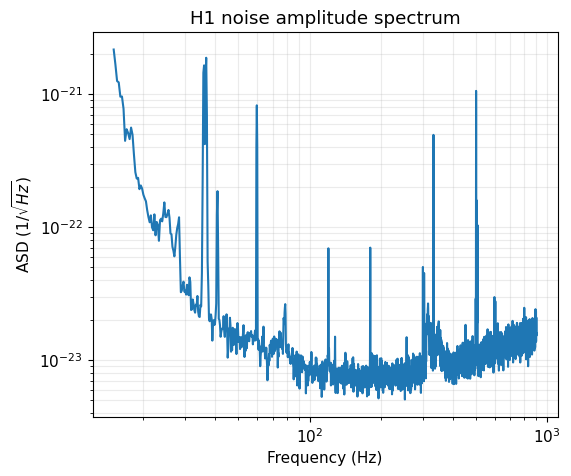

Frequency bin width (Hz): 0.25


In [ ]:
psd = estimate_psd(h1)

freq = psd.sample_frequencies

mask = (freq >= 15) & (freq <= 900)

fig,ax=plt.subplots(figsize = (6, 5))
ax.loglog(freq[mask], np.sqrt(psd[mask]))
ax.set(xlabel='Frequency (Hz)',ylabel=r'ASD ($1/\sqrt{Hz}$)',title='H1 noise amplitude spectrum')
ax.grid(True,which='both',alpha=.25)
plt.show()
print('Frequency bin width (Hz):',psd.delta_f)

**Exercise:** Try segments of 2, 4, and 8 s. Compare smoothness and narrow lines. Note: different window/averaging choices also matter.

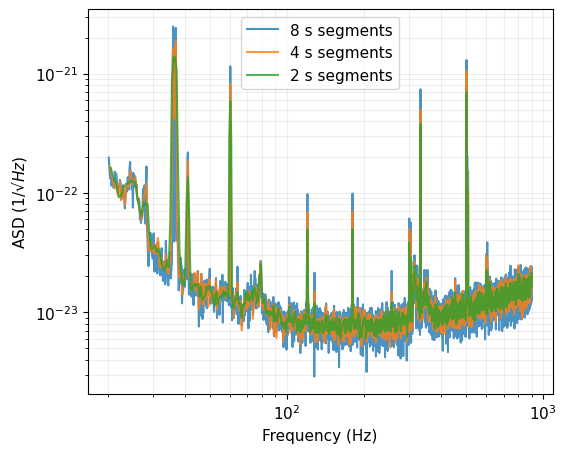

In [28]:
fig,ax=plt.subplots(figsize = (6, 5))

for seconds in [8, 4, 2]:

    k=int(seconds*SAMPLING_FREQ)
    
    estimate=welch(h1, seg_len=k, seg_stride=k//2)
    f=estimate.sample_frequencies
    sel=(f>20)&(f<900)

    ax.loglog(f[sel],np.sqrt(estimate[sel]),label=f'{seconds} s segments',alpha=.8)
    
ax.set_xlabel('Frequency (Hz)')
plt.ylabel('ASD ($1/√Hz$)')
plt.legend()
plt.grid(alpha=.2,which='both')
plt.show()

## Whitening: flattening the noise spectrum
Whitening divides by the estimated amplitude spectrum (with appropriate Fourier normalization), making frequency bands contribute more equally. Edge transients are common after filtering: always crop the edges before interpretation.

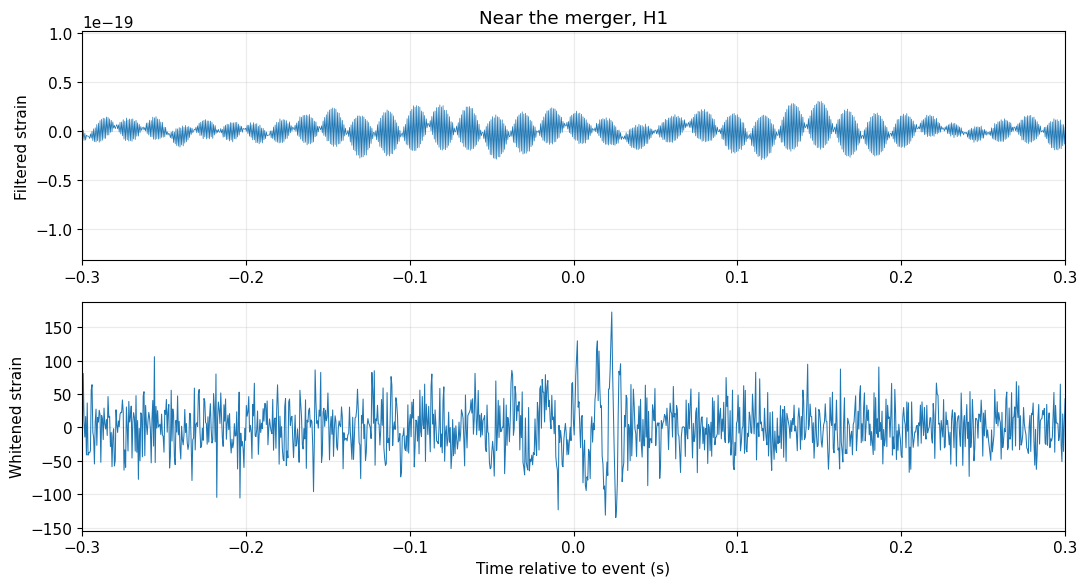

In [41]:
whiten_h1 = h1.whiten(4, 4, low_frequency_cutoff=20)
whiten_l1 = l1.whiten(4, 4, low_frequency_cutoff=20)

fig,axs=plt.subplots(2,1,figsize=(11,6))
axs[0].plot(h1.sample_times-GPS,h1,lw=0.5)
axs[0].set(xlim=(-.3,.3),ylabel='Filtered strain',title='Near the merger, H1')
axs[1].plot(whiten_h1.sample_times-GPS,whiten_h1,lw=0.75)
axs[1].set(xlim=(-.3,.3),xlabel='Time relative to event (s)',ylabel='Whitened strain')

for a in axs:
    a.grid(alpha=.25)

plt.tight_layout()
plt.show()

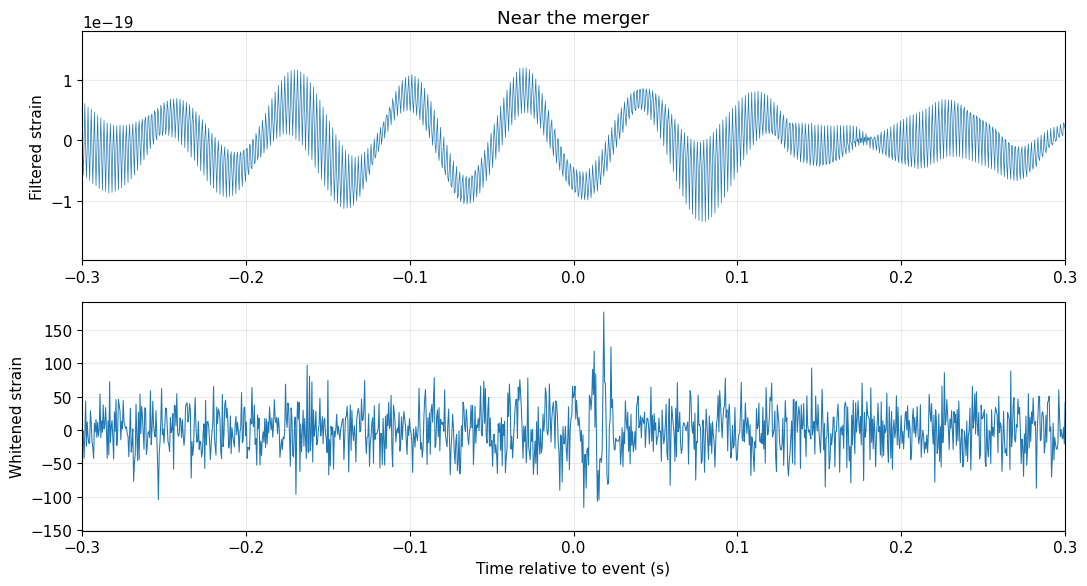

In [42]:
fig,axs=plt.subplots(2,1,figsize=(11,6))
axs[0].plot(l1.sample_times-GPS,l1,lw=0.5)
axs[0].set(xlim=(-.3,.3),ylabel='Filtered strain',title='Near the merger')
axs[1].plot(whiten_l1.sample_times-GPS,whiten_l1,lw=0.75)
axs[1].set(xlim=(-.3,.3),xlabel='Time relative to event (s)',ylabel='Whitened strain')

for a in axs:
    a.grid(alpha=.25)

plt.tight_layout()
plt.show()

In [39]:
# _ = plt.hist(whiten_h1.data * (2*len(h1)), bins = 25, histtype = 'step')

### Questions
1. Why use PSD weighting instead of treating all Fourier frequencies equally?
2. Why should we not estimate a PSD from only a few samples near a candidate event?
3. How does an ASD differ from a PSD?

**Takeaway:** GW searches must model *noise* as carefully as the *signal*.